# Choosing terms from the data

This page is for readers who have completed
the beginner route ([Quickstart](quickstart.ipynb) and
[gamboost](gamboost.ipynb)) and have a data frame with many columns for which
they want base learners proposed from the observed values. It documents the
functions that build a formula from the data (`classify_columns`,
`suggest_terms`, `autospec`, `expand_pairs`, `screen_interactions`): how each
chooses a term for a column, how to declare knowledge the frame does not
contain, and how to inspect and override every proposal before fitting. The [Budgeted specification search](specification_search.ipynb) page covers search sessions that compare many such specifications under a fit budget.

`classify_columns`, `suggest_terms` and `autospec` propose base learners from
the observed values of each column. An indicator needs one contrast, a
40-level grouping can use 40 unpenalized indicators or a random effect with
fewer effective degrees of freedom, and a threshold effect can use a stump (a regression tree with one split).
These proposals help construct a formula for a wide frame, but the choice
also depends on what a column measures.

The learner codes used on this page name candidate terms in a formula. `bols(x)` is a linear term in `x`. `bbs(x)` is a P-spline, a smooth curve in `x` built from a B-spline basis with a roughness penalty. `btree(x)` is a regression tree term, by default a stump. `brandom(g)` is a random effect with one shrunken coefficient per level of the grouping `g`. `bmono(x)` is a P-spline constrained to increase or decrease. The [base learners](../methodology/base_learners.ipynb) page describes the others.

An unsuitable basis can cause numerical failure as well as a poor fit. For
example, tensoring two spline bases over indicator columns gives a
degenerate design and can prevent convergence.

The functions in `mboostrs.terms` automate exactly the decisions that can be
made from a column's shape. The decisions that need knowledge the frame does
not contain cannot be guessed, but they can be declared, and `autospec`
accepts the declarations directly: `monotone={"spend": "increasing"}` writes
a monotone P-spline for that column, `coordinates=("lon", "lat")` merges two
columns into one spatial surface, and `adjacency=` and `basis=` attach a
neighbourhood matrix or a custom design that a formula string cannot carry.
A declared term is fixed: comparisons report its validation-loss difference
from alternatives, but retain the declaration. For a whole specification of your own,
`prior=` plays the same role.

Everything the functions return comes back in editable form, as a string, a
ranking or a specification, and can be overridden before the real fit.

The functions correspond to tasks as follows:

```{list-table}
:header-rows: 1

* - You want to
  - Call
  - What you get
* - see and veto the per-column reasoning
  - `classify_columns(data)`
  - one `ColumnKind` per predictor: levels, kind, suggested term
* - accept the defaults and take the string
  - `suggest_terms(data)`
  - the main-effect right-hand side
* - have the family and the step count `mstop` (the number of boosting steps) guessed too, and optionally measured against
    alternatives
  - `autospec(data, response)`
  - `(formula, learners, family, mstop)`, plus a report when given a budget
* - declare mechanism knowledge — a monotone effect, a coordinate pair, a
    neighbourhood — and have the specification built around it
  - `autospec(..., monotone=, coordinates=, adjacency=, basis=)`
  - your terms as fixed incumbents, the other guesses measured
* - supply a whole specification you believe in and have the probes (held-out comparisons of the guesses) measure against it
  - `autospec(..., prior=...)`
  - your specification as the baseline
* - write interaction terms for pairs you have in mind
  - `expand_pairs(data, pairs=...)`
  - the `%X%` or varying-coefficient term for each pair
* - find out which pairs are worth having in mind at all
  - `screen_interactions(data, residual)`
  - every candidate pair ranked by out-of-sample evidence
```

For an initial specification, call `autospec` with a fit budget and inspect
its report before fitting the recommendation. The body-fat study
[](../cases/autospec_bodyfat.ipynb) shows this workflow and a change to a
column declaration after reviewing its proposed treatment.

One specification is assembled here in workflow order. The columns are read (`classify_columns`), the first formula
written (`suggest_terms`, with `smooth=` adjusting it), the remaining guesses
made and measured (`autospec` and its probes, with declarations and folds
shaping what is measured), and the specification extended beyond main effects
(`expand_pairs`, `screen_interactions`). The running frame is simulated, so
at each stage the answer can be checked against what was built into it.

In [1]:
import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

rng = np.random.default_rng(11)
n = 600
survey = {
    "income": rng.lognormal(10.5, 0.4, n),              # continuous, skewed
    "age": rng.integers(18, 80, n).astype(float),        # continuous, integer
    "visits": rng.integers(0, 6, n).astype(float),       # a few ordered levels
    "region": rng.integers(0, 9, n).astype(float),       # a grouping
    "urban": rng.integers(0, 2, n).astype(float),        # an indicator
}
survey["y"] = (np.log(survey["income"]) + 0.02 * survey["age"]
               + 0.4 * survey["urban"] + rng.normal(0, 0.3, n))

## Column classification: `classify_columns` and `suggest_terms`

Every route through the table above starts in the same place: reading the
columns. The running example is a simulated survey of 600 rows, built so that
we know what each column is meant to be. `classify_columns` reads the frame
and returns, for each predictor, its distinct values, the kind it is taken
for, and the term suggested. The decision comes with its reasoning, so you
can disagree with it before it reaches a formula.


In [2]:
display(pl.DataFrame([
    {"column": c.name, "levels": c.levels, "kind": c.kind, "suggested term": c.term}
    for c in mb.classify_columns(survey, response="y")]))

column,levels,kind,suggested term
str,i64,str,str
"""income""",600,"""continuous""","""bbs(income, df=4.0)"""
"""age""",62,"""continuous""","""bbs(age, df=4.0)"""
"""visits""",6,"""continuous""","""bbs(visits, df=4.0)"""
"""region""",9,"""continuous""","""bbs(region, df=4.0)"""
"""urban""",2,"""binary""","""bols(urban)"""


Reading down the table: `income` and `age` come back continuous, `visits`
and `region` are read as groupings even though they are stored as numbers,
and `urban` becomes a single indicator contrast. Each answer follows from
the column's shape alone.

A column with two distinct values gets `bols`: one coefficient represents
the contrast between its values, and there are no intermediate values on
which to estimate a curved effect.

Between three and twelve distinct whole numbers are read, provisionally, as
levels. `visits` and `region` therefore get `brandom`, which estimates one
shrunken effect per value; `bols(visits)` would instead fit a single slope
across the numeric codes, with no indicator columns and no
separate group means. If the values are counts or equally spaced ordinal scores, say
so by choosing that slope or a smooth explicitly. Two distinct values remain a
single indicator contrast, and the upper cutoff is
`terms.CATEGORICAL_MAX_LEVELS`, currently 12.

Above twelve values a whole-number column can still be a grouping code:
district or clinic numbers are stored exactly like ages. When
`classify_columns` is given the response, it reads such a column against it
with `label_evidence`. The mean response is taken at each value. For a
grouping code, those means vary more than sampling noise explains, and codes
next to each other are no more alike than any two codes; for a measurement
with a smooth effect, neighbouring values have similar means. A column that
behaves as labels gets `brandom`, and any other keeps `bbs`.

Everything else is treated as continuous and gets `bbs`. The whole-number
requirement carries weight here: a measurement that happens to take few
distinct values in a small sample is still a measurement, and coding it as
levels would discard the ordering. `age` is integer-valued with 62 distinct
values and does not behave as labels, so it stays continuous.

The string `suggest_terms` returns is a formula right-hand side and can be
passed to `gamboost` as it stands. The printout also reports which learners were selected at least once in the 400 boosting steps (`mstop` = 400, step length 0.1): every learner appears, including the two groupings that have no effect on the response (`visits` and `region`). Keeping noise out is the stopping rule's
job ([](model_selection.ipynb)), not the term choice's; what the term choice
controls is what each learner is able to represent.

In [3]:
rhs = mb.suggest_terms(survey, response="y")
print(rhs)

model = mb.gamboost(f"y ~ {rhs}", data=survey, family=mb.Gaussian(),
                    control=mb.boost_control(400, 0.1))
print(f"\nfitted; learners selected at least once: "
      f"{sorted(set(model.selected))}")

bbs(income, df=4.0) + bbs(age, df=4.0) + bbs(visits, df=4.0) + bbs(region, df=4.0) + bols(urban)

fitted; learners selected at least once: ['age', 'income', 'region', 'urban', 'visits']


## Smooth type: `smooth=`

The rules settle each column's kind; within the continuous ones a question
stays open — what shape of effect to prepare for. `smooth=` answers it in
advance, and leaves the rest of the formula alone. The choice matters when
the shape of the effect is in doubt: a P-spline assumes the effect varies
smoothly, while a stump makes no such assumption and fits a threshold where
a spline would average across it.

`smooth="menu"` offers `bols`, `bbs` and `btree` for each continuous column
and leaves the choice to boosting's selection step, which at every iteration
picks the learner that best fits the current residual. The decision is then
made from the data, per variable, rather than in advance.

The term written for `income` follows `smooth=`, and the term for `urban` stays `bols(urban)`, because `smooth=` touches continuous columns only. Under the menu all three learners appear for `income`.


In [4]:
for smooth in ("bbs", "btree", "menu"):
    terms = {c.name: c.term for c in mb.classify_columns(survey, response="y",
                                                         smooth=smooth)}
    print(f"smooth={smooth!r:8s} income -> {terms['income']}")
    print(f"{'':17s} urban  -> {terms['urban']}   (unchanged)")

smooth='bbs'    income -> bbs(income, df=4.0)
                  urban  -> bols(urban)   (unchanged)
smooth='btree'  income -> btree(income)
                  urban  -> bols(urban)   (unchanged)
smooth='menu'   income -> bols(income) + bbs(income, df=4.0) + btree(income)
                  urban  -> bols(urban)   (unchanged)


A menu is something to ask for when you do not know whether an effect is
smooth or sharp, not a default. Every extra candidate is another learner the
selection step scores at every iteration, and offering three learners where
one would do triples that cost and dilutes the comparison.

## Formula, family and `mstop` in one call: `autospec`

`autospec(data, response)` proposes terms, a family and a stopping iteration.
It returns `(formula, learners, family, mstop)`, which can be passed to
`gamboost`. The returned learners are constructed from the formula, so the formula alone specifies the same model.

With the default `budget=0`, these choices follow column and response
characteristics. A positive `budget` allows fits that compare alternatives;
`folds=` supplies their validation splits. `prior=` supplies a baseline
specification, and declarations such as `monotone=` preserve constraints
from subject knowledge. Three data checks also run when the fit budget is zero.

The family follows the response's storage: a boolean or `{0, 1}` numeric
column becomes `Binomial`, a factor of three or more levels `Multinomial`,
whole non-negative numbers `Poisson` (unless their median exceeds 1,000,
where a count and a rounded measurement cannot be told apart and the response
is treated as a positive measurement), a strictly positive response
`GammaReg`, and everything else `Gaussian`. With a budget, the family probe
then measures the guess: the spread of held-out residuals against the fitted
level decides between Poisson and `NBinomial`, or between `GammaReg` and
`Gaussian`, and if a non-Gaussian family has higher held-out squared error than `Gaussian`,
`autospec` selects the Gaussian family. If you already
know which loss to fit, `family=` overrides the guess. One term rule looks at
a column's distribution rather than its storage: a right-skewed column
(sample skewness above 2) gets `bbs(log(x))` when strictly positive and
`bbs(sqrt(x))` when it holds zeros. A P-spline's knots are spaced evenly over
the column's range, so on the raw scale most of the curve would sit over a
handful of extreme rows, and a cross-validation fold that holds those rows
out would extend the curve across a range it never saw. When predictions
beyond the training range should stay flat, write `bbs(ecdf(x))` by hand: it
places the knots at quantiles of `x` (see [](real_data.ipynb)).

Running `autospec` on the survey returns the four objects and the fit they specify.


In [5]:
formula, learners, family, mstop = mb.autospec(survey, "y")
print("formula:", formula)
print("family: ", type(family).__name__, " mstop:", mstop)

fit = mb.gamboost(formula, data=survey, learners=learners, family=family,
                  control=mb.boost_control(mstop))
print("selected:", sorted(set(fit.selected)))

formula: y ~ bbs(income, df=4.0) + bbs(age, df=4.0) + bbs(visits, df=4.0) + bbs(region, df=4.0) + bols(urban)
family:  Gaussian  mstop: 100
selected: ['age', 'income', 'region', 'urban']


### Measuring the guesses: `budget=`

The default guesses all come from the frame's storage: a float column gets
`bbs`, a non-negative integer response gets `Poisson`. Guesses of that kind
can be wrong in ways storage cannot see. An overdispersed count looks like a
Poisson count; a threshold effect looks like a smooth one.

`budget=` is how many model fits `autospec` may spend to measure the guesses
instead. It is zero by default, and at zero no comparison fits are run.
Given a budget, the return value carries the evidence and `report()` prints
it, marking each answer as measured or defaulted.

Two responses are never guessed at. A two-level label column is refused with
a reason, because `Binomial` reads a numeric or boolean column and a label
column must be recoded first. A declared ordered categorical with three or
more levels is not silently turned into a numeric scale: the formula uses
`brandom`, `autospec` warns that this ignores the declared order, and
`classify_columns(...)[i].explain()` lists the alternatives, which are
explicit numeric scores carried by `bols`, `bbs` or `bmono`.

In [6]:
# Own names: a notebook shares one namespace, and `n`/`rng` belong
# to the cells above.
claim_rng = np.random.default_rng(3)
spend = claim_rng.uniform(-3, 3, size=300)
claim_mu = np.exp(0.4 + 0.9 * (spend > 0))
counts = {
    "spend": spend,
    "claims": claim_rng.negative_binomial(
        2.0, 2.0 / (2.0 + claim_mu)).astype(float),
}

print(mb.autospec(counts, "claims", budget=120, mstop=60).report())

/Users/fcela/src/public_github/mboostrs/python/mboostrs/autospec.py:608: UserWarning: response 'claims' has whole-number values stored as floating point; autospec assumes counts and selects Poisson. Pass family=Gaussian() for a rounded continuous measurement or declare another known family.
  return _autospec_body(**arguments, step=step, auto_nu=auto_nu)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_autospec.py:3291: UserWarning: predict() with default type='link' returns the log-mean for NBinomial; pass type='response' for response scale.
  own = np.asarray(fit.predict(newdata=self.data, which=learner),
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 50 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 48 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_workflow.py:191: RuntimeWarning: the training risk rose on 55 of 200 boosting steps (largest rise 0.00185 of the risk before it); the final risk is 0.192% above its minimum at step 103: the step nu=1 is too large for this loss's curvature, so the path does not consistently descend. Use a smaller nu, or step='line_search', which chooses each step's length on the loss.
  return function(*args, **kwargs)
/Users/fcela/src/public_github/mboostrs/python/mboostrs/autospec.py:608: UserWarning: response 'claims' has whole-number values stored as floating point; autospec assumes counts and selects Poisson. Pass family=Gaussian() for a rounded continuous measurement or declare another known family.
  return _autospec_body(**arguments, step=step, auto_nu=auto_nu)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_autospec.py:3291: UserWarning: predict() with default type='link' returns the log-mean for NBinomial; pass type='response' for response scale.
  own = np.asarray(fit.predict(newdata=self.data, which=learner),
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 50 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


autospec: claims ~ btree(spend)

folds: 5 random folds (rows, not groups, are held out)

response: Poisson counts (inferred from whole-number values, 16 distinct; if they are rounded measurements pass family=Gaussian())

data hygiene (no fit -- scans only)
  no constant, heavily missing or mistyped column

family: NBinomial — held-out Pearson dispersion 2.84: the counts are more spread than a Poisson mean allows, so NBinomial carries the extra variance; boosted, NBinomial predicts as well as Gaussian within sampling noise (held-out squared error 8.17 against 8.18, standard error of the difference 0.046) (300 held-out rows)

shapes (held-out risk, shared folds)
  spend: btree over bbs: btree 2.1057, bbs 2.1191, bols 2.1206 — 3.1% less held-out risk, 2.6 paired fold standard errors

structure: not screened
  interaction rule: heredity none
column screen (marginal, no fit; 1 candidate columns): curve: spend
pre-exploration (native, 1 probe fit(s); 0 candidate pairs): pair proposals only; 

### Dropping terms and refitting: `deselect=` and `refit="reml"`

With a budget, `autospec` tunes the step count, then drops the terms whose
share of the tuned fit's risk reduction is under 1% and tunes the step count
again (`deselect=True`, the default). A cross-validated boosting fit keeps
every column its path updated even once, so without this step most noise
columns stay in the recommendation. The smaller formula is checked on the
same folds: if its cross-validated risk is more than 1% above the full
formula's, the small terms together carry signal, and only the smallest are
dropped, as many as keep the rise within 1% (a bisection over the terms
ordered by share). For example, twenty terms contributing 0.5% each account for 10% of the
path's risk reduction, so dropping all of them can lose substantial signal.
The report lists the dropped terms, their shares, the change in held-out risk
and any small terms kept, under `terms:`. Declared terms are never dropped.

`rec.fit(data, refit="reml")` fits the recommendation and refits its terms jointly as one penalized regression, choosing each term's smoothness by REML (restricted maximum likelihood), which removes the shrinkage
that early stopping leaves on every effect. It returns the refit, whose
`summary()` gives each term's test.

The simulated frame has one curved effect, one linear effect and six columns of noise.

In [7]:
noise_rng = np.random.default_rng(5)
frame = {f"x{i}": noise_rng.uniform(-1, 1, 500) for i in range(1, 9)}
frame["y"] = (np.sin(np.pi * frame["x1"]) + frame["x2"]
              + noise_rng.normal(0, 0.5, 500))

noisy = mb.autospec(frame, "y", budget=200, seed=0)
print(noisy.formula)
print(noisy.evidence["deselect"].sentence)

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 51 is within 5% of the search cap 51; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 50 is within 5% of the search cap 51; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


y ~ bbs(x1, df=4.0) + bbs(x2, df=4.0)
6 of 8 terms dropped for less than 1% of the risk reduction (bbs(x4, df=4.0) 0.00%, bbs(x6, df=4.0) 0.03%, bbs(x5, df=4.0) 0.12%, bbs(x8, df=4.0) 0.19%, bbs(x3, df=4.0) 0.26%, bbs(x7, df=4.0) 0.55%); dropping them changed the held-out risk by -2.1%; mstop tuned again for the rest


The recommendation keeps the two columns that carry an effect; the six
noise columns are dropped, each with a share below 1%. The refit gives each kept
term its smoothing parameter and a test:

In [8]:
noisy.fit(frame, refit="reml").summary()

Penalized refit (REML)
==============================================================================
Link:                identity   REML score:         2409.0096
Observations:             500   Degrees of freedom:   12.0035
Scale:                 0.2385   Log-likelihood:     -345.6103
==============================================================================
term                edf   ref_df         F  p_value
---------------------------------------------------
bbs(x1, df=4.0)  8.3514  10.1298   94.6114  < 2e-16
bbs(x2, df=4.0)  1.6521   2.0461  329.4055  < 2e-16
==============================================================================
The terms were selected on the same data, so the p-values are conditional on
that selection and smaller than those of a model fixed in advance.

A Poisson, negative binomial or gamma response in the hundreds can make the
first fixed-length boosting steps overflow the inverse link. `autospec` then
repeats its measurements with a line search for the step length
(`step="line_search"`), says so in the report, and the recommendation's
control carries the line search, so `rec.fit` replays it. Pass `step=` to fix
the rule yourself.

### Data hygiene checks

Some findings need no model fit at all, so they appear at every budget, zero
included: a column holding one value, a column missing in most rows, and a
float column holding two or three distinct values. Each changes what a fit
means.

A constant column produces no learner and is dropped from the specification;
a term written for it would fit the intercept a second time. A column missing
in two rows of three drops those rows for *every* term, so the model trains
on the remainder, and whether that remainder is the population the question
is about is a decision, not a detail. A float column holding two values is a
group label that arrived as a number: `bbs` would interpolate between labels
that have no midpoint, so `bols` is the term and the finding says why.

The scan also reports columns that are not predictors. A text column with a
different label on almost every row is an identifier, and it is left out. A
column of whole numbers that differ on almost every row is an identifier or a
count, and it is kept and flagged. A column named like the response, such as
`sd_rent` next to `rent`, is a statistic of the response or a parallel
outcome. A second column that records the grouping another column already
records is left out. A whole-number code that behaves as labels is fitted with
`brandom`, and the finding names `groups=`.

The simulated frame is built to contain the first three: `branch` is constant,
`tenure` is missing in two rows of three, and `region` arrives as a float
with two values.

In [9]:
# The same counts, with three columns a real extract tends to carry.
messy = dict(counts)
messy["region"] = np.where(claim_rng.random(300) < 0.5, 1.0, 2.0)
messy["tenure"] = np.where(np.arange(300) < 200, np.nan,
                           claim_rng.normal(size=300))
messy["branch"] = np.full(300, 7.0)

print(mb.autospec(messy, "claims").report())

autospec: claims ~ bbs(spend, df=4.0) + bols(region) + bbs(tenure, df=4.0)

response: Poisson counts (inferred from whole-number values, 16 distinct; if they are rounded measurements pass family=Gaussian())

data hygiene (no fit -- scans only)
  region: 2 distinct values (1, 2) in a float column -- read as groups, not as a measured quantity: a spline would interpolate between labels. Declare measurements="region" if the values are ordered quantities
  tenure: 200 of 300 rows missing (67%) -- a fit drops those rows for every term, so the model is trained on the remainder -- decide whether that remainder is the population you mean
  branch: one value (7) in 300 rows -- no learner is produced for it: a term on a constant fits the intercept twice

family: Poisson — from the response's dtype; not measured

shapes: not measured; each column keeps the learner its dtype implies

structure: not screened
  interaction rule: heredity none
column screen (marginal, no fit; 3 candidate columns): ste

/Users/fcela/src/public_github/mboostrs/python/mboostrs/autospec.py:608: UserWarning: response 'claims' has whole-number values stored as floating point; autospec assumes counts and selects Poisson. Pass family=Gaussian() for a rounded continuous measurement or declare another known family.
  return _autospec_body(**arguments, step=step, auto_nu=auto_nu)


### Declared terms: `monotone=`, `coordinates=`, `adjacency=`, `basis=`

Use declarations to supply a known effect constraint, coordinate pair,
neighbourhood matrix or custom basis. `autospec` retains a declared term even
when an alternative predicts better. Its shape comparison reports the
validation-loss difference so you can reconsider the declaration explicitly. The example declares an increasing effect of `dose` twice, once where the response does rise with dose and once where
it falls.

In [10]:
decl_rng = np.random.default_rng(4)
dose = np.sort(decl_rng.uniform(0, 10, 200))
rising = dose + decl_rng.normal(scale=0.3, size=200)
falling = 10 - dose + decl_rng.normal(scale=0.3, size=200)

for y, label in ((rising, "y rises with dose"), (falling, "y falls with dose")):
    frame = {"dose": dose, "y": y}
    rec = mb.autospec(frame, "y", family=mb.Gaussian(),
                      monotone={"dose": "increasing"}, budget=120, mstop=40)
    row = next(r for r in rec.evidence["shapes"] if r.column == "dose")
    print(f"{label}:")
    print(f"  {row.sentence}")

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 50 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 49 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 48 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


y rises with dose:
  bmono(dose, constraint=increasing, df=4.0) stands (declared): bols 0.0942, bmono(dose, constraint=increasing, df=4.0) 0.0943, bbs 0.0944, btree 0.1566 — no alternative beats it by 2% of the held-out risk


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:189: RuntimeWarning: tune_mstop: the chosen mstop=1 has a cross-validated risk of 8.04562, within 1.0% of the intercept-only risk of 8.04562 (mstop=0; relative gap 0.00%). The curve is flat and the fit is close to a constant: the terms add little that the out-of-fold risk can see at this sample size. Compare with the constant model before reporting the fitted effects. Pass flat_tolerance=None to silence this check, or a different tolerance.
  return fn(*args, **kwargs)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 50 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 48 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 47 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 49 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:189: RuntimeWarning: tune_mstop: the chosen mstop=1 has a cross-validated risk of 8.04562, within 1.0% of the intercept-only risk of 8.04562 (mstop=0; relative gap 0.00%). The curve is flat and the fit is close to a constant: the terms add little that the out-of-fold risk can see at this sample size. Compare with the constant model before reporting the fitted effects. Pass flat_tolerance=None to silence this check, or a different tolerance.
  return fn(*args, **kwargs)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:189: RuntimeWarning: tune_mstop: the chosen mstop=1 has a cross-validated risk of 8.04562, within 1.0% of the intercept-only risk of 8.04562 (mstop=0; relative gap 0.00%). The curve is flat and the fit is close to a constant: the terms add little that the out-of-fold risk can see at this sample size. Compare with the constant model before reporting the fitted effects. Pass flat_tolerance=None to silence this check, or a different tolerance.
  return fn(*args, **kwargs)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:189: RuntimeWarning: tune_mstop: the chosen mstop=1 has a cross-validated risk of 8.04562, within 1.0% of the intercept-only risk of 8.04562 (mstop=0; relative gap 0.00%). The curve is flat and the fit is close to a constant: the terms add little that the out-of-fold risk can see at this sample size. Compare with the constant model before reporting the fitted effects. Pass flat_tolerance=None to silence this check, or a different tolerance.
  return fn(*args, **kwargs)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:189: RuntimeWarning: tune_mstop: the chosen mstop=1 has a cross-validated risk of 8.04562, within 1.0% of the intercept-only risk of 8.04562 (mstop=0; relative gap 0.00%). The curve is flat and the fit is close to a constant: the terms add little that the out-of-fold risk can see at this sample size. Compare with the constant model before reporting the fitted effects. Pass flat_tolerance=None to silence this check, or a different tolerance.
  return fn(*args, **kwargs)


y falls with dose:
  bmono(dose, constraint=increasing, df=4.0) stands (declared): bols 0.0895, bbs 0.0912, btree 0.1475, bmono(dose, constraint=increasing, df=4.0) 8.0456 — the constraint costs 98.9% less held-out risk, 12.8 paired fold standard errors against bols


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:189: RuntimeWarning: tune_mstop: the chosen mstop=1 has a cross-validated risk of 8.04562, within 1.0% of the intercept-only risk of 8.04562 (mstop=0; relative gap 0.00%). The curve is flat and the fit is close to a constant: the terms add little that the out-of-fold risk can see at this sample size. Compare with the constant model before reporting the fitted effects. Pass flat_tolerance=None to silence this check, or a different tolerance.
  return fn(*args, **kwargs)


Both calls retain the declared increasing `bmono` term. In the increasing
response example, no alternative improves validation loss enough to pass the
replacement rule. In the decreasing response example, enforcing an increasing
effect substantially raises held-out risk; the report expresses the increase
as a percentage. `autospec` reports this conflict but requires the caller to
change the declaration.

`coordinates=("lon", "lat")` works the same way for a spatial surface, and
`adjacency=` and `basis=` attach the matrices a formula string cannot carry;
their alternatives are compared, but the declared terms are retained.

### Baseline specification: `prior=`

A declaration states one fact about one column. A prior states a whole
specification. `prior=` takes it as a formula string, or as a mapping with
`formula` and optionally `family` and `mstop`, and makes it the baseline: a
candidate then has to beat that baseline by the same margin any other
alternative would, so the report measures your choice against the
alternatives instead of discarding it. The example starts with `bols(spend)` and a Poisson family. Here the
shape comparison replaces the line with a tree, and the family comparison
selects a negative-binomial loss. The printed recommendation gives the
selected step count.

Terms the prior wrote outside the shape catalogue — a monotone spline, a
user basis — are fixed incumbents, exactly as under the declaration
keywords; catalogue terms such as `bols(spend)` are measured like any other
incumbent and replaced when something beats them by the margin. Stating
`family` skips the family probe; the step count is still measured when the
budget allows, and the measured value is the one returned.

The returned object also fits itself: `rec.fit(data)` builds the model from
the formula, learners, family and step count it just chose, so none of the
four has to be carried by hand. Unpacking it as the four values still works
where you want to change one of them first.


In [11]:
kept = mb.autospec(messy, "claims", budget=120, mstop=60,
                   prior="claims ~ bols(spend)")
formula, _, family, mstop = kept
print("formula:", formula, "| family:", type(family).__name__,
      "| mstop:", mstop)
print("measured:", kept.measured, "| fits spent:", kept.fits)

model = kept.fit(messy)
print("fitted at mstop", model.mstop,
      "selecting", sorted(set(model.selected)))

/Users/fcela/src/public_github/mboostrs/python/mboostrs/autospec.py:608: UserWarning: response 'claims' has whole-number values stored as floating point; autospec assumes counts and selects Poisson. Pass family=Gaussian() for a rounded continuous measurement or declare another known family.
  return _autospec_body(**arguments, step=step, auto_nu=auto_nu)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_autospec.py:3291: UserWarning: predict() with default type='link' returns the log-mean for NBinomial; pass type='response' for response scale.
  own = np.asarray(fit.predict(newdata=self.data, which=learner),
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 50 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 48 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_workflow.py:191: RuntimeWarning: the training risk rose on 55 of 200 boosting steps (largest rise 0.00185 of the risk before it); the final risk is 0.192% above its minimum at step 103: the step nu=1 is too large for this loss's curvature, so the path does not consistently descend. Use a smaller nu, or step='line_search', which chooses each step's length on the loss.
  return function(*args, **kwargs)
/Users/fcela/src/public_github/mboostrs/python/mboostrs/autospec.py:608: UserWarning: response 'claims' has whole-number values stored as floating point; autospec assumes counts and selects Poisson. Pass family=Gaussian() for a rounded continuous measurement or declare another known family.
  return _autospec_body(**arguments, step=step, auto_nu=auto_nu)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_autospec.py:3291: UserWarning: predict() with default type='link' returns the log-mean for NBinomial; pass type='response' for response scale.
  own = np.asarray(fit.predict(newdata=self.data, which=learner),
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 50 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


formula: claims ~ btree(spend) | family: NBinomial | mstop: 7
measured: ('family', 'shapes', 'mstop', 'whole_model') | fits spent: 157
fitted at mstop 7 selecting ['spend']


### Cross-validation folds: `folds=`, `seed=` and `groups=`

A probe is a held-out comparison of one class of guesses: the family, shape, `mstop` and
interaction probes each score their candidates on rows the candidate did not
train on. `folds=` is that held-out split, shared by all four. The default is
5-fold on `seed=`, which treats the rows as interchangeable. Repeated
measurements on one unit, and rows in time order, are not interchangeable: a
held-out row then has near-copies among the rows that trained the model, and
every score the probes report is better than the model would be on data it
has not seen.

`grouped_folds`, `rolling_folds`, `blocked_folds` and `stratified_folds`
build a split that keeps that structure, and passing one as `folds=` sends it
to all four probes. For groups there is a shorter route: `groups=` names the
group column, fits it with `brandom`, and builds the grouped folds.

In the simulated frame, twenty branches contribute fifteen rows each, and each
branch sits at its own level. The branch codes are the whole numbers 0 to 19.
The comparison supplies random row folds explicitly in the first call,
overriding automatic group detection, and declares `groups="branch"` in the
second. `cv_weights(type="kfold", B=5, seed=0)` constructs five reproducible
row folds; its matrix entries are training weights for each fold:

In [12]:
branch_rng = np.random.default_rng(11)
# Sparse codes (3 apart): a 0-based code spanning its whole range reads
# as a count (#313) and never reaches the label logic this demo shows.
branch_id = np.repeat(np.arange(20) * 3, 15).astype(float)
branch_level = np.repeat(branch_rng.normal(scale=1.5, size=20), 15)
branch_x = branch_rng.normal(size=300)
panel = {"x": branch_x, "branch": branch_id,
         "y": 0.8 * branch_x + branch_level
              + branch_rng.normal(scale=0.4, size=300)}

# Explicit row folds override automatic group detection.
row_folds = mb.cv_weights(len(branch_id), type="kfold", B=5, seed=0)
by_rows = mb.autospec(panel, "y", budget=90, mstop=80, folds=row_folds)
by_branch = mb.autospec(panel, "y", budget=90, mstop=80, groups="branch")
for label, rec in (("random folds", by_rows), ('groups="branch"', by_branch)):
    print(f"{label:16s} mstop {int(rec.mstop):3d}   {rec.formula}")
    print(f"{'':16s} {rec.folds_description}")
    print(f"{'':16s} mstop: {rec.evidence['mstop'].sentence}")

branch_finding = next(h for h in by_rows.hygiene if h.kind == "integer-labels")
print()
print(branch_finding)
rows_mstop, branch_mstop = int(by_rows.mstop), int(by_branch.mstop)
rows_extended = "extended" in by_rows.evidence["mstop"].sentence

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 149 is within 5% of the search cap 149; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


random folds     mstop 220   y ~ bols(x) + brandom(branch, df=4.0)
                 supplied by the caller
                 mstop: mstop=220 — the linear rival's shared-fold path (cap 298), adopted by the whole-model comparison
groups="branch"  mstop  22   y ~ bbs(x, df=4.0) + brandom(branch, df=4.0)
                 5 grouped folds holding whole groups of branch out (declare folds= for another design)
                 mstop: the cross-validated risk turns at 22 of 200 iterations tried

branch: 20 whole-number values behave as labels: the mean response varies between values 26.1 times as much as noise explains (77.5 standard deviations above no signal), and adjacent values differ as much as arbitrary pairs (adjacency ratio 1.33) -- fitted with brandom rather than a smooth. The folds you supplied decide how these groups are held out


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3185: UserWarning: optimal mstop 60 is within 5% of the search cap 60; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


Both calls fit the branch as a group, `brandom(branch)`: the scan read the
codes as labels from the response alone, and its finding, printed last, says
so before any model is fitted. What differs is what the probes measure. On
random folds a held-out row shares its branch with rows the model trained on,
and more steps keep paying: the step count comes back as {eval}`rows_mstop`.
With whole branches held out it is {eval}`branch_mstop`, the count that applies
to a branch the model has not seen. The fold line in each report records which
of the two questions the numbers answer.

## Preliminary exploration: `preexploration`

A budgeted `autospec` search fits one preliminary ensemble of depth-4 trees
before comparing effect shapes. Permuting each column measures its contribution
to the ensemble's squared-error prediction loss. Partial dependence averages
predictions with a column held at specified values; it describes the ensemble's
estimated effect after averaging over the other columns. Both operations, the
ensemble fit and the subsequent diagnostics are computed in the Rust core.

The default `preexploration="native"` uses the package's tree learner. For a
Gaussian response, agreement between marginal diagnostics and the ensemble's
partial dependence can omit an implausible shape: a nearly linear effect is
compared with a line and a smooth, for example. The incumbent remains in the
comparison, declared constraints retain all their cost comparisons, and weak or
ambiguous evidence retains the full catalogue. Columns are considered in order
of permutation importance when the fit budget is limited. For other families,
response-scale diagnostics propose pairs without pruning link-scale shapes.

The same ensemble supplies interaction candidates among its eight most important
columns, using Friedman's H² to measure departure from additive partial effects.
Its one fit is charged once and reused by the interaction probe. Pair adoption
reserves the fits needed for held-out validation before tuning the candidate;
without that budget, the pairs remain suggestions in the report. Partial
dependence is evaluated on at most 100 training rows for at most 32 columns;
columns outside that limit retain all shape alternatives. No preliminary model
is fitted with `budget=0` or when the remaining budget cannot cover it and the
following comparisons. A failed native screen is reported and leaves the shape
catalogue open.

Use `preexploration="off"` to compare the full shape search with only the
residual-based pair screen. `preexploration="hessboost"` uses the optional
histogram boosting engine with the same diagnostics and comparison rules. A
source build enables it with `maturin develop --release --features hessboost`;
a build without that feature raises an error when asked to use it. The optional
engine is pinned to hessboost 0.1.1. The ordinary build does not compile hessboost.
The report and `recommendation.evidence["preexploration"]` record the engine,
importance order, proposed shapes, sampling sizes and pair scores. Importance
is the increase in mean squared prediction error after permutation, in squared
response units; a negative value is retained rather than interpreted as evidence
of a useful predictor. H² is dimensionless, and interaction variance has squared
response units.

Screening can miss an effect, and partial dependence can extrapolate across
unlikely combinations of correlated predictors. Agreement checks limit pruning
but do not eliminate either limitation. Every proposed replacement still passes
the usual held-out comparison; those folds also participate in adaptive search,
so their minimum risk is descriptive. Evaluate the whole fit-and-search procedure
on separate test data or within outer resampling folds.

The [methodology chapter](../methodology/preexploration.ipynb) defines the diagnostics.
The [controlled case](../cases/preexploration_shapes.ipynb) checks recovered effects,
and the [benchmark](../cases/benchmark_preexploration.ipynb) compares complete searches.


## Interaction terms: `expand_pairs`

The main-effect terms give one term per column and one surface per declared coordinate pair. The frame may hold more — an effect that appears
only when two columns act together. `expand_pairs` writes the interaction
terms, and the learner for a pair follows from its two margins, for the same
reason the main effects do: the margin types determine which learner can represent the pair.


In [13]:
pairs = [("income", "age"), ("income", "urban"), ("urban", "visits")]
for term in mb.expand_pairs(survey, response="y", pairs=pairs):
    print(term)

bbs(income, df=2.5, knots=5) %X% bbs(age, df=2.5, knots=5)
bbs(income, by=urban, df=4.0)
bbs(visits, by=urban, df=4.0)


Two continuous margins give a tensor product `%X%`, a spline surface over
both. Each margin is written with five inner knots (`knots=5`, 9 columns),
so the surface has 81 columns; with the default 20 knots it would have
24 × 24 = 576, and every boosting step would solve a system of that size,
about 25 times slower on the benchmark's interaction task for no gain in
accuracy. Where one margin is an indicator a surface is not defined, so the term
becomes a varying coefficient `bbs(a, by=b)`, the smooth in `a` scaled by
`b`. Two indicators give a product `bols(a, by=b)`.

Marginal degrees of freedom **multiply**, and the range you can choose from
has a hard floor. A second-difference penalty leaves constants and straight
lines unpenalised, so each margin has a two-dimensional null space and their
tensor has a four-dimensional one. A term asked for df=4 is asked for exactly
its null space: the smoothing parameter is not identified there, the fit
collapses onto that null space, and what comes back is a bilinear surface
$a + bx + cy + dxy$ whatever the data look like. Measured on a
$\sin(1.5x)\cos(1.5y)$ surface, a df=4 tensor explains $R^2$ 0.0001 of it;
at df=9 it explains 0.92.

That floor is why `expand_pairs` defaults to `marginal_df=2.5`, giving
df=6.25, and warns if you ask for a product at or below 4.

The floor also has a consequence for selection, and it is a real limit rather
than a tuning preference. `bbs(a, df=4) %X% bbs(b, df=4)` carries df=16 and is
selected ahead of `df=4` main effects for reasons unrelated to signal, and
the obvious repair of matching the numbers fails, because a tensor with df=4
is not a surface. If comparable degrees of freedom matter more than
curvature, use a tree or a varying-coefficient term; neither has this null-space floor.

`kind="tree"` uses a two-variable `btree` instead. It fits axis-aligned
thresholds rather than a smooth surface, builds no dense design matrix, and
is much cheaper; on data whose structure is sharp rather than smooth it also
fits better.

In [14]:
print(mb.expand_pairs(survey, response="y", pairs=[("income", "age")],
                      kind="tree", maxdepth=4)[0])

btree(income, age, maxdepth=4)


## Screening interactions: `screen_interactions`

`expand_pairs` writes the pairs you name; choosing which to name is the
harder half, and naming all of them is expensive. Expanding every pair costs
$p(p-1)/2$ learners, each scored at every iteration: 21 columns give 210
interaction terms, and 59 give 1711. `screen_interactions` ranks the
candidates before any of them is fitted.

Both columns of a pair are binned into quantile cells on half the rows, the
cell means of the residual are taken there, and the residual sum of squares
those means remove is measured on the other half. A pair that fits only noise
removes nothing out of sample and scores at or below zero, so the ranking is
not a count of flexibility. No model is fitted; the cost is binning. The
residual the screen works on is what the additive fit left behind.

The zero line marks no held-out improvement. A positive score means the pair
reduces residual mean squared error on the evaluation half-sample.


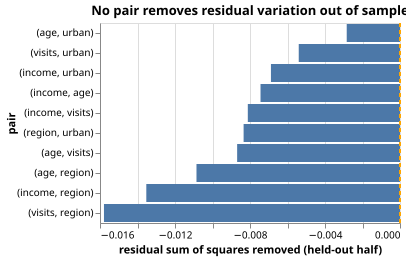

In [15]:
additive = mb.gamboost(f"y ~ {mb.suggest_terms(survey, response='y')}",
                       data=survey, family=mb.Gaussian(),
                       control=mb.boost_control(400, 0.1))
residual = survey["y"] - np.asarray(additive.predict()).ravel()

ranked = mb.screen_interactions(survey, residual=residual, response="y")
survey_scores = pl.DataFrame({
    "pair": [f"({s.left}, {s.right})" for s in ranked],
    "removed": [s.removed for s in ranked],
})
bars = alt.Chart(survey_scores).mark_bar().encode(
    x=alt.X("removed").title("residual sum of squares removed (held-out half)"),
    y=alt.Y("pair").sort("-x"),
    tooltip=["pair", alt.Tooltip("removed", format=".3f")],
)
zero = alt.Chart(survey_scores).mark_rule(color="orange", strokeDash=[4, 3]).encode(
    x=alt.datum(0),
)
(bars + zero).properties(
    title="No pair removes residual variation out of sample",
)

This survey has no interaction in it, so every pair scores at or below zero
and the correct action is to carry none. A positive score is evidence
for a pair, and a uniformly negative set of scores is evidence that none is
warranted.

`screen_interactions` returns scores instead of selecting pairs because the
number of pairs to test depends on the validation budget and evidence
threshold. A practical starting rule is to retain positive-scoring pairs up
to a specified budget.

In [16]:
keep = [(s.left, s.right) for s in ranked if s.removed > 0][:10]
print(f"pairs worth carrying: {keep if keep else 'none'}")

with_interactions = mb.suggest_terms(survey, response="y")
if keep:
    with_interactions += " + " + " + ".join(
        mb.expand_pairs(survey, response="y", pairs=keep, kind="tree"))
print(f"\nformula: y ~ {with_interactions}")

pairs worth carrying: none

formula: y ~ bbs(income, df=4.0) + bbs(age, df=4.0) + bbs(visits, df=4.0) + bbs(region, df=4.0) + bols(urban)


## Screening an interaction built into the data

The same frame with a genuine interaction added shows the other half of the
behaviour. Here the response depends on `income` multiplied by `urban`, and
nothing else changes. The bars are drawn on the same scale and against the
same zero line as the survey's screen, so the two charts can be compared
directly.

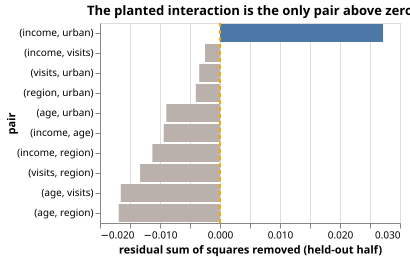

In [17]:
crossed = dict(survey)
crossed["y"] = (np.log(crossed["income"]) * crossed["urban"]
                + 0.02 * crossed["age"] + rng.normal(0, 0.3, n))

base = mb.gamboost(f"y ~ {mb.suggest_terms(crossed, response='y')}", data=crossed,
                   family=mb.Gaussian(), control=mb.boost_control(400, 0.1))
resid = crossed["y"] - np.asarray(base.predict()).ravel()
found = mb.screen_interactions(crossed, residual=resid, response="y")
crossed_scores = pl.DataFrame({
    "pair": [f"({s.left}, {s.right})" for s in found],
    "removed": [s.removed for s in found],
})
bars = alt.Chart(crossed_scores).mark_bar().encode(
    x=alt.X("removed").title("residual sum of squares removed (held-out half)"),
    y=alt.Y("pair").sort("-x"),
    color=alt.condition(alt.datum.removed > 0, alt.value("#4c78a8"),
                        alt.value("#bab0ac")),
    tooltip=["pair", alt.Tooltip("removed", format=".3f")],
)
zero = alt.Chart(crossed_scores).mark_rule(color="orange", strokeDash=[4, 3]).encode(
    x=alt.datum(0),
)
(bars + zero).properties(
    title="The planted interaction is the only pair above zero",
)

The pair `(income, urban)`, built into the simulated data, is the only bar above the zero line; every
other pair scores where it did on the survey, at or below zero.

`autospec(..., budget=, interactions="adopt")` runs this screen on the
response-scale residual of its main-effect fit, adds each pair term it
proposes to the formula, and cross-validates the step count again for the
larger model. The default, `interactions="report"`, lists the pairs and
leaves the formula additive.

## Limitations of the column rules

The rules are heuristics about column *shape*, and a column's shape does not
carry its meaning. A postcode stored as an integer with nine values is
categorical by the rule and by intent, while a satisfaction score from 1 to 9
is categorical by the rule and ordinal by intent, and `brandom` discards the
ordering. Read the `classify_columns` table before using its output.

Degrees of freedom are equalised only among the learners these functions
write. `btree` carries no `df` argument at all, so a menu mixing `btree` with
penalised learners cannot be balanced the way two penalised learners can.
This affects selection, and no argument controls it.

A useful sequence is to review `classify_columns`, edit the suggested terms,
declare effects supported by subject-matter knowledge, use `autospec` to
compare the remaining terms, and screen proposed pairs before fitting them. Choosing the
stopping iteration and judging the resulting fit are covered in
[](model_selection.ipynb) and [](diagnostics.ipynb).


## Screening discontinuities: `screen_discontinuities`

The tools above do not detect a jump across a boundary in two columns. The
smooth fit absorbs most of a step, because its two marginal curves tilt to
follow it; an axis-aligned threshold on either column alone shows no gain in
cross-validation; and `screen_interactions` ranks surfaces, not lines. `screen_discontinuities` scans for the jump directly:
steps in one column and steps across lines in two standardized columns,
over sixteen directions, at interior quantile thresholds. Every candidate
is a step indicator against a smooth background, fitted in the Rust core.

Candidate ranking and scoring use different halves of the rows. Candidates are ranked on one half of
the rows; the reported `z` of the winner comes from the other half, which
selection never touched. Under no jump anywhere that `z` is a standard
normal, so the gate (`|z| >= 2` with a positive held-out `gain`) fires
on about 4.6% of no-jump screens however many boundaries were searched.
`type_z` distinguishes a jump from a steep smooth crossing: the step is refitted against a
background that already contains smooth terms along the projection, and a
crossing's step collapses where a jump's does not.

In [18]:
# A planted diagonal regime: calls jump by 2 across east = 0.45 + 0.35 north.
jump_rng = np.random.default_rng(12)
territory = {name: jump_rng.uniform(0, 1, 800) for name in ("north", "east", "depth")}
territory["calls"] = (2.0 * (territory["east"] > 0.45 + 0.35 * territory["north"])
                      + 1.5 * territory["north"] + 1.0 * territory["east"]
                      + jump_rng.normal(0, 0.5, 800))

smooth = mb.gamboost("calls ~ bbs(north) + bbs(east) + bbs(depth)", territory,
                     family=mb.Gaussian(), control=mb.boost_control(100, 0.1))
residual = territory["calls"] - np.asarray(smooth.predict()).ravel()

hits = mb.screen_discontinuities(territory, residual, response="calls")
print(hits[0])
print(f"typed as a jump: {hits[0].typed_jump}, flagged: {hits[0].flagged}")

east > 0.4263 + 0.3722*north: jump +1.292 (se 0.102), z +12.60, gain +0.1253, type_z +12.18, type_gap_t +5.5, ratio 0.81
typed as a jump: True, flagged: True


The screen names the boundary on the original scale, `east > 0.4263 +
0.3722 north` against the true line `0.45 + 0.35` used to simulate the data. The jump it finds is the one the
smooth fit could not absorb: 1.292 of the 2.0 jump built into the simulated data (the marginal curves
tilted to follow the rest). `z` is 12.6, far past the screening threshold of 2, and `type_z` is 12.2: the step survives a background that
already contains smooth terms along the projection, so this is a jump,
not a steep crossing.

The boundary is a candidate like any other, and scoring it shows why
naming the line matters. With the indicator built from the screen's
boundary, `compare_specifications` gives the additive baseline an
out-of-fold risk of 0.4796; adding `bols` on the indicator takes it to
0.2998, a change of -0.1798 with a paired standard error of 0.0171, while
`btree(north, east)`, the candidate an analyst would use when the
boundary is unknown, does not reduce out-of-fold risk (+0.0025, within noise of zero). A
depth-limited tree approximates a diagonal coarsely; the named line is
the hypothesis itself. When the screen does not flag, the jump branch of
the search is over: the structure a `reference_gap` still reports belongs
to a smooth or interaction term, and "no jump in these columns" is a
result the report can carry.

## Comparative studies

[Repeated validation of specification search](../cases/specification_search_validation.ipynb) measures whether the documented search improves prediction or simplifies a model across independent training samples.